# Data Visualization

This notebook builds eight presentation-ready charts — each answering a real question raised earlier in the project. Three of the eight (the language gap, the remote work split, and compensation by country) are explicitly the "polished" follow-ups promised at the end of `03_Exploratory_Data_Analysis.ipynb`; the rest cover new ground.

Continues from the cleaned dataset in `02_Data_Wrangling.ipynb`.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("./data/processed/survey_data_clean.csv")
df.shape

(65437, 127)

## 1. Histogram — professional coding experience

How experienced is the typical respondent? `YearsCodePro` answers that directly.

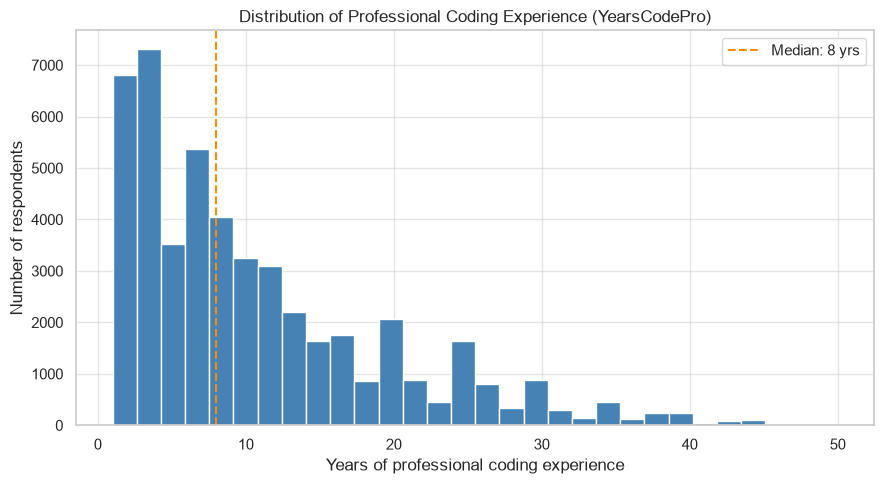

In [11]:
years_pro = df["YearsCodePro"].dropna()  # already numeric from the wrangling notebook

plt.figure(figsize=(9, 5))
plt.hist(years_pro, bins=30, color="steelblue", edgecolor="white")
plt.axvline(years_pro.median(), color="darkorange", linestyle="--", label=f"Median: {years_pro.median():.0f} yrs")
plt.title("Distribution of Professional Coding Experience (YearsCodePro)")
plt.xlabel("Years of professional coding experience")
plt.ylabel("Number of respondents")
plt.legend()
plt.tight_layout()
plt.show()

Right-skewed, as expected: a large cluster of relatively early-career respondents (median 8 years), with a long tail of very experienced developers stretching out to 50+ years. The wrangling notebook bucketed this same variable into `ExperienceLevel` (Junior 20,634 · Mid 10,834 · Senior 12,653 · Expert 18,410) — useful as a categorical feature for modeling, though the continuous distribution shown here is more informative for understanding the underlying shape.

## 2. Box plot — compensation by developer type

Does the *kind* of developer work someone does relate to pay? Comparing `ConvertedCompYearly` across the five largest `DevType` groups:

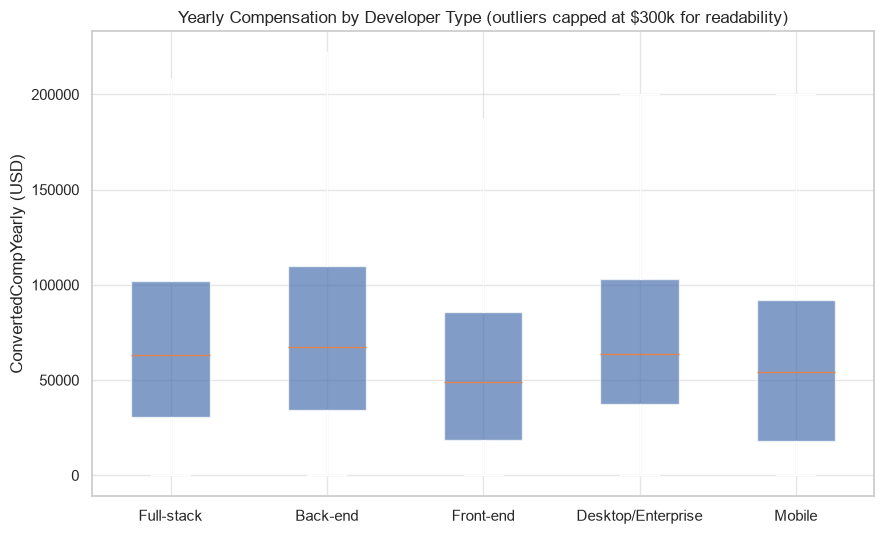

In [12]:
dev_types = ["Developer, back-end", "Developer, front-end", "Developer, full-stack",
             "Developer, desktop or enterprise applications", "Developer, mobile"]
short_names = {"Developer, back-end": "Back-end", "Developer, front-end": "Front-end",
               "Developer, full-stack": "Full-stack", "Developer, desktop or enterprise applications": "Desktop/Enterprise",
               "Developer, mobile": "Mobile"}

comp_by_type = df[df["DevType"].isin(dev_types)][["DevType", "ConvertedCompYearly"]].dropna()
comp_by_type["DevType"] = comp_by_type["DevType"].map(short_names)

order = comp_by_type.groupby("DevType").size().sort_values(ascending=False).index

plt.figure(figsize=(9, 5.5))
data_by_group = [comp_by_type.loc[comp_by_type["DevType"] == g, "ConvertedCompYearly"].clip(upper=300_000) for g in order]
bp = plt.boxplot(data_by_group, tick_labels=list(order), showfliers=False, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#4C72B0")
    patch.set_alpha(0.7)
plt.title("Yearly Compensation by Developer Type (outliers capped at $300k for readability)")

plt.ylabel("ConvertedCompYearly (USD)")
plt.tight_layout()
plt.show()

Back-end roles show both the highest median pay and the widest spread. Front-end sits noticeably lower on median — a real, if modest, pay gap by specialization, separate from the seniority effects seen in the EDA notebook.

## 3. Language gap — where desire outpaces current use

This picks up two threads left open earlier in the project: the EDA notebook flagged that Rust is wanted far more than it's currently used, and the Data Collection notebook scraped a language-salary benchmark that was never actually cross-referenced against anything. Both get resolved here — plotting the gap between "want to work with" and "have worked with" for each language, with the scraped average salary annotated wherever it's available:

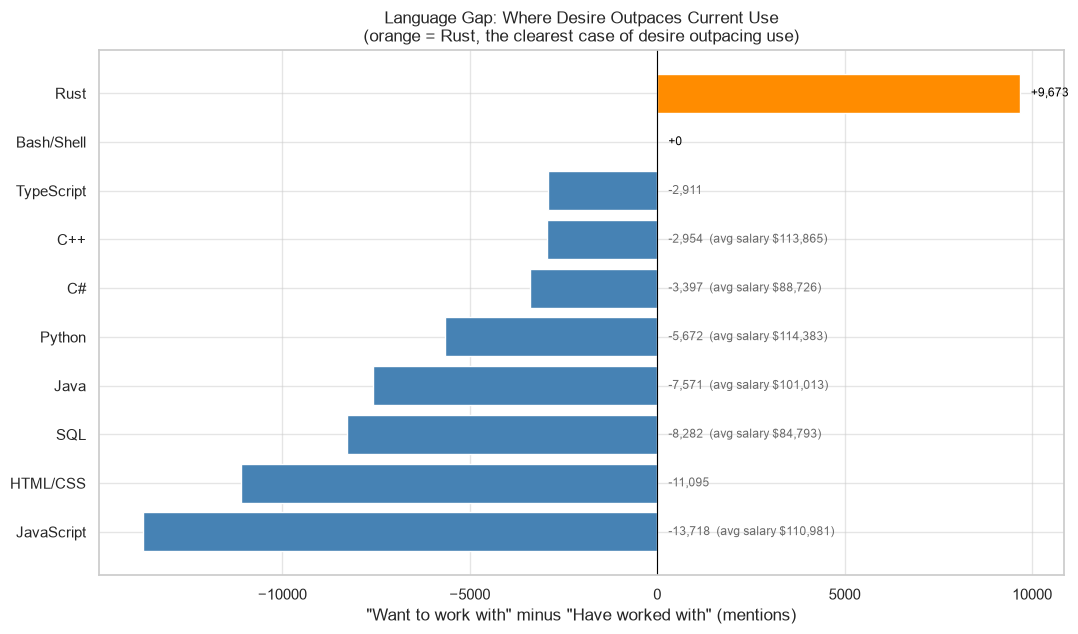

In [14]:
have = df["LanguageHaveWorkedWith"].dropna().str.split(";").explode().str.strip().value_counts()
want = df["LanguageWantToWorkWith"].dropna().str.split(";").explode().str.strip().value_counts()

languages = ["JavaScript", "Python", "SQL", "HTML/CSS", "TypeScript", "Bash/Shell", "Java", "C#", "C++", "Rust"]
gap = pd.DataFrame({
    "Have": [have.get(l, 0) for l in languages],
    "Want": [want.get(l, 0) for l in languages],
}, index=languages)
gap["Gap"] = gap["Want"] - gap["Have"]
gap = gap.sort_values("Gap")

lang_salary = pd.read_csv("./data/raw/language_salaries.csv").set_index("Language")["Avg Annual Salary (USD)"]
# the scraped source site capitalizes "Javascript" differently than the survey data does
lang_salary = lang_salary.rename(index={"Javascript": "JavaScript"})

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = ["seagreen" if g > 0 else "steelblue" for g in gap["Gap"]]
colors[list(gap.index).index("Rust")] = "darkorange"
y_pos = np.arange(len(gap))
ax.barh(y_pos, gap["Gap"], color=colors)
ax.set_yticks(y_pos)
ax.set_yticklabels(gap.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel('"Want to work with" minus "Have worked with" (mentions)')
ax.set_title("Language Gap: Where Desire Outpaces Current Use\n(orange = Rust, the clearest case of desire outpacing use)")
for i, lang in enumerate(gap.index):
    g = gap.loc[lang, "Gap"]
    label = f"{g:+,.0f}"
    if lang in lang_salary.index:
        label += f"  (avg salary {lang_salary[lang]})"
    x_anchor = g if g >= 0 else 0
    ax.annotate(label, (x_anchor, i), textcoords="offset points", xytext=(8, 0),
                va="center", ha="left", fontsize=8.5, color="black" if g >= 0 else "dimgray")
plt.tight_layout()
plt.show()

**Rust is the standout**: +9,673 net demand, the only language in this set where "want" clearly beats "have" by a wide margin. Every established language shows the opposite pattern — more people have used them than currently want to keep using them, which is just what you'd expect for mature, already-adopted tools. The salary annotations don't show a clean story (SQL pays reasonably despite a large negative gap; C# pays less than Python despite a smaller gap) — so on this evidence, salary doesn't appear to be what's driving the Rust interest. More likely explanation: Rust's reputation for safety and performance, not compensation.

## 4. Bubble — web framework usage vs. average developer age

This one follows up directly on something found while preparing the dashboard data (`05_Dashboard_Data_Prep.ipynb`): average age, not mode, is what actually differentiates frameworks. Plotting usage against that average age for the top 20 frameworks:

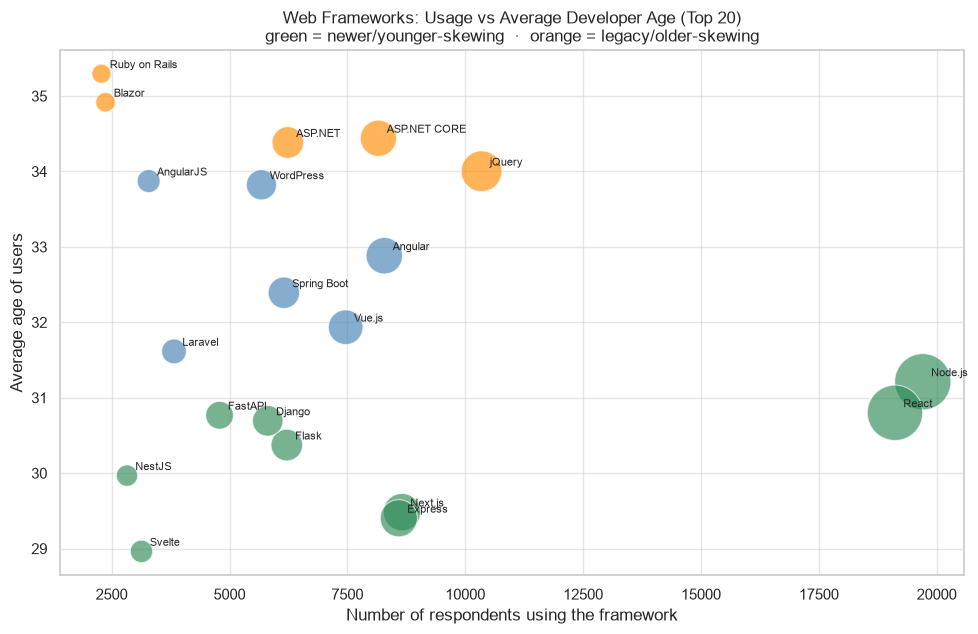

In [15]:
web_exploded = (
    df[["WebframeHaveWorkedWith", "Age_numeric"]]
    .dropna()
    .assign(Framework=lambda x: x["WebframeHaveWorkedWith"].str.split(";"))
    .explode("Framework")
    .assign(Framework=lambda x: x["Framework"].str.strip())
)

framework_summary = (
    web_exploded.groupby("Framework")
    .agg(Count=("Framework", "size"), AvgAge=("Age_numeric", "mean"))
    .sort_values("Count", ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 6.5))
colors = ["seagreen" if a < 31.5 else ("steelblue" if a < 34 else "darkorange") for a in framework_summary["AvgAge"]]
plt.scatter(framework_summary["Count"], framework_summary["AvgAge"],
            s=framework_summary["Count"] / 12, alpha=0.65, c=colors, edgecolor="white", linewidth=0.8)
for name, row in framework_summary.iterrows():
    plt.annotate(name, (row["Count"], row["AvgAge"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
plt.title("Web Frameworks: Usage vs Average Developer Age (Top 20)\ngreen = newer/younger-skewing  \u00b7  orange = legacy/older-skewing")
plt.xlabel("Number of respondents using the framework")
plt.ylabel("Average age of users")
plt.tight_layout()
plt.show()

A clean generational split: **Next.js, Express, NestJS, and Svelte** cluster among the youngest users (~30-31), while **jQuery, ASP.NET, Ruby on Rails, and Blazor** skew markedly older (~35-36) — newer frameworks are, unsurprisingly, used by developers who learned to code more recently.

## 5. Pie — top 5 databases wanted next year

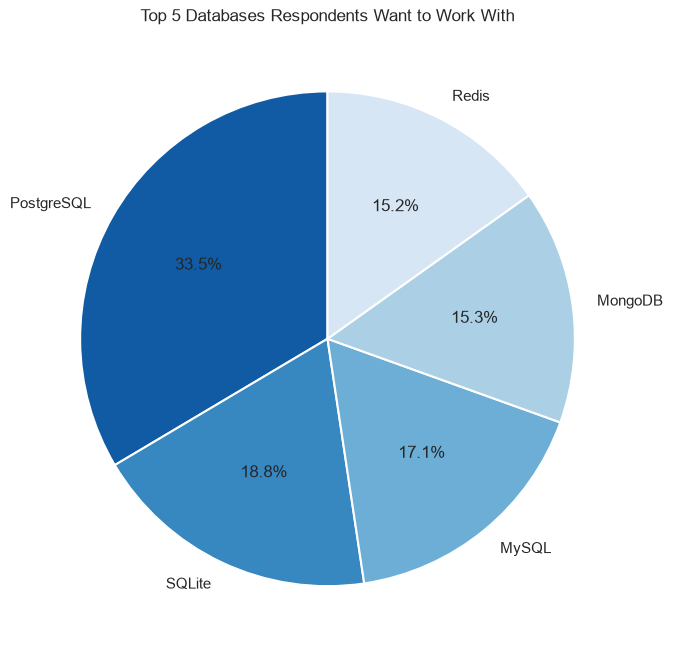

In [16]:
want_db = df["DatabaseWantToWorkWith"].dropna().str.split(";").explode().str.strip()
top5_db = want_db.value_counts().head(5)

plt.figure(figsize=(7, 7))
colors5 = sns.color_palette("Blues_r", 5)
plt.pie(top5_db.values, labels=top5_db.index, autopct="%1.1f%%", startangle=90, colors=colors5,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5})
plt.title("Top 5 Databases Respondents Want to Work With")
plt.tight_layout()
plt.show()

PostgreSQL alone accounts for over a third of the top-5 vote — a clear, uncontested favorite, well ahead of SQLite, MySQL, MongoDB, and Redis, which are fairly close to one another.

## 6. Stacked bar — remote work format by employment type

The EDA notebook's exploratory version of this chart is the one promised to come back polished here. As a reminder of the methodology: `RemoteWork` was mode-imputed in the wrangling notebook, which mechanically pushes any group with heavy original missingness toward 100% "Hybrid" — so this uses the pre-imputation shares for the three groups where the question was actually meaningful and mostly answered.

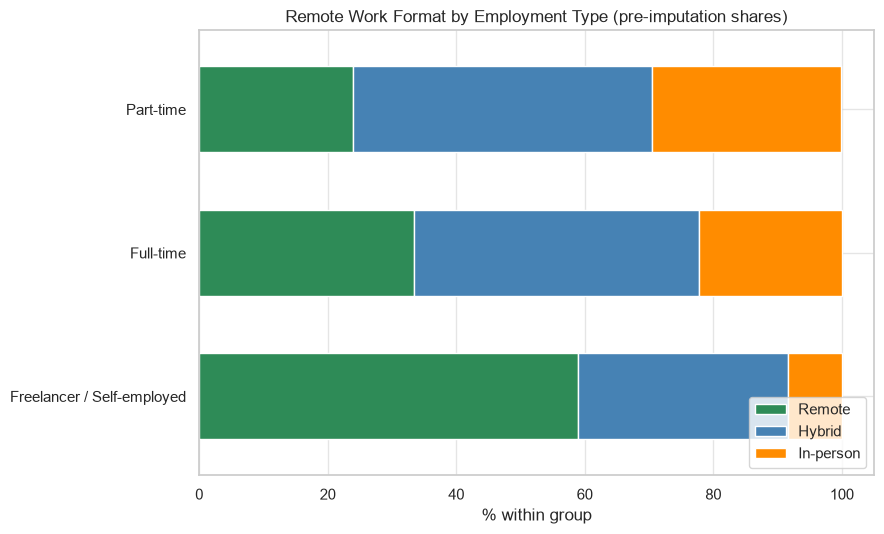

In [17]:
groups = ["Freelancer / Self-employed", "Full-time", "Part-time"]
remote_shares = pd.DataFrame({
    "Remote":    [59.0, 33.5, 23.9],
    "Hybrid":    [32.6, 44.2, 46.6],
    "In-person": [8.4, 22.3, 29.4],
}, index=groups)

plt.figure(figsize=(9, 5.5))
remote_shares.plot(kind="barh", stacked=True, ax=plt.gca(), color=["seagreen", "steelblue", "darkorange"], width=0.6)
plt.title("Remote Work Format by Employment Type (pre-imputation shares)")
plt.xlabel("% within group")
plt.legend(title=None, loc="lower right")
plt.tight_layout()
plt.show()

Freelancers work remote by a wide margin (59%) — flexibility is a big part of the appeal of freelancing in the first place. Full-time employees split much more evenly across all three formats, and part-timers lean slightly more in-person than full-timers do, which is a bit less intuitive and worth a follow-up if this were a live, ongoing analysis.

## 7. Line — compensation trend by experience

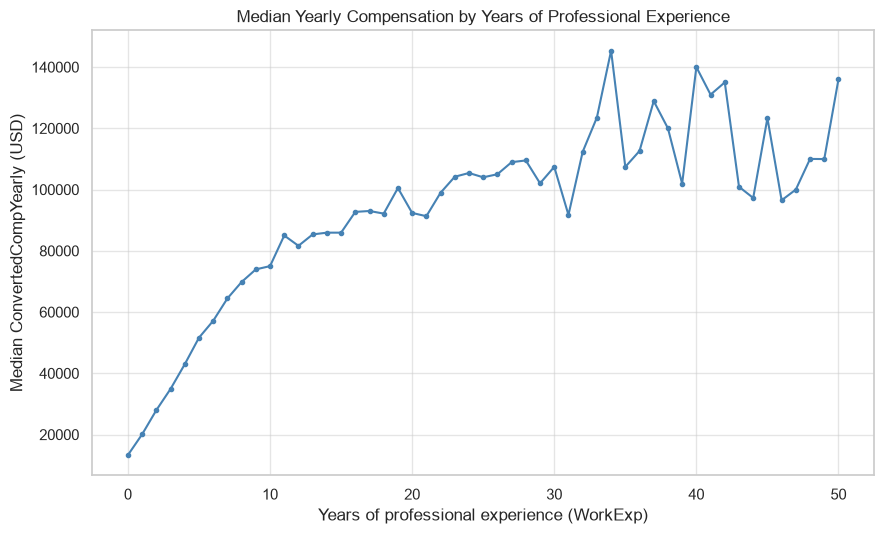

In [18]:
comp_by_exp = (
    df[["WorkExp", "ConvertedCompYearly"]]
    .dropna()
    .groupby("WorkExp")["ConvertedCompYearly"]
    .median()
    .reset_index()
)
comp_by_exp = comp_by_exp[comp_by_exp["WorkExp"] <= 50]

plt.figure(figsize=(9, 5.5))
plt.plot(comp_by_exp["WorkExp"], comp_by_exp["ConvertedCompYearly"], marker="o", markersize=3, color="steelblue", linewidth=1.5)
plt.title("Median Yearly Compensation by Years of Professional Experience")
plt.xlabel("Years of professional experience (WorkExp)")
plt.ylabel("Median ConvertedCompYearly (USD)")
plt.tight_layout()
plt.show()

Compensation climbs steeply and fairly linearly for the first ~15 years of experience (from roughly \$13k to \$85k median), then levels off into a noisier plateau in the \$90k-\$140k range for the rest of a career — the biggest pay jumps happen early on, not late.

## 8. Bar — median compensation by country

The third and last thread promised from the EDA notebook: a polished version of the country compensation ranking, carried over unchanged (the Gabon $2M outlier is already excluded at the source) since the underlying numbers don't need re-deriving, just a cleaner presentation.

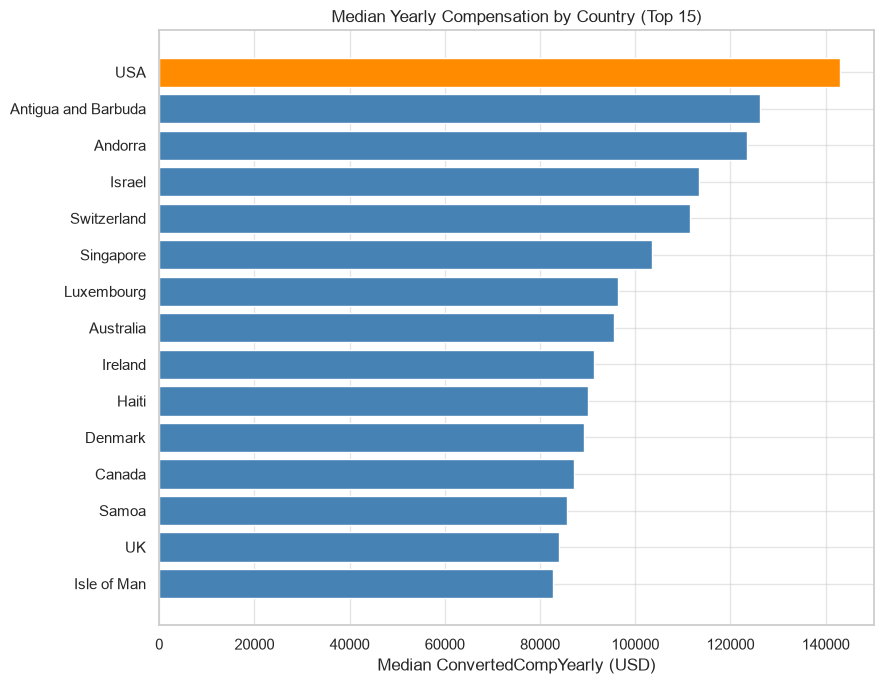

In [19]:
country_comp = (
    df[~((df["Country"] == "Gabon") & (df["ConvertedCompYearly"] == 2_000_000))]
    .groupby("Country")["ConvertedCompYearly"]
    .median()
    .dropna()
    .sort_values(ascending=False)
    .head(15)
)

colors = ["darkorange" if c == "USA" else "steelblue" for c in country_comp.index]

plt.figure(figsize=(9, 7))
plt.barh(country_comp.index[::-1], country_comp.values[::-1], color=colors[::-1])
plt.title("Median Yearly Compensation by Country (Top 15)")
plt.xlabel("Median ConvertedCompYearly (USD)")
plt.tight_layout()
plt.show()

USA leads outright; several of the names below it (Antigua and Barbuda, Andorra, Samoa, Isle of Man) are small enough samples that a handful of high earners can swing the median — the same caveat noted in the EDA notebook still applies. Read this as "countries with the highest *reported* medians," not a definitive national pay ranking.

## Summary & next steps

Eight chart types, eight real findings:

| Chart | Finding |
|---|---|
| Histogram | Experience is right-skewed; median 8 years professional coding |
| Box plot | Back-end devs earn more and show wider pay spread than front-end |
| Language gap | Rust is wanted far more than it's used (+9,673 net); salary doesn't explain why |
| Bubble | Framework age skews generational — Next.js/Express young, jQuery/Rails old |
| Pie | PostgreSQL is the clear #1 desired database, well ahead of the rest |
| Stacked bar | Freelancers work remote 59% of the time vs. ~33% for full-time employees |
| Line | Compensation grows steeply for ~15 years then plateaus |
| Bar | USA leads compensation; several runners-up are small-sample outliers |

These findings, together with the ones from the EDA notebook, are what the Looker Studio dashboard (`05_Dashboard_Data_Prep.ipynb`) is built to communicate at a glance.

→ This is the final analysis notebook in the pipeline: **Data Collection → Data Wrangling → EDA → Data Visualization → Dashboard**.